# Experimento A completo: sección 4.1 y presupuestos de la sección 4.3

Este notebook ejecuta las dos políticas greedy y tres inicializaciones del mismo
MILP: cold, Benefit start y Density start. Los tres tratamientos se resuelven a
**1, 5, 15, 60 y 600 segundos**. El benchmark de las tablas y figuras A1/A8 es
600 s. Cada búsqueda empieza de nuevo; el óptimo de una corrida larga no se
entrega como start de una corta.

El modo inicial es **`full`**: 150 instancias, 2250 optimizaciones y 300 greedy.
Antes de ejecutar todas las celdas, revisar los parámetros y la carpeta de salida.
`pilot` usa una instancia y los mismos cinco presupuestos para verificar todo.
No hay otra fase de referencia de 600 s. Los resultados se guardan localmente.

La corrida completa se guarda en `ttap_runs_paper_2000dpi`, separada de las
carpetas anteriores. `RESUME=True` permite retomarla si se interrumpe.


In [1]:
from pathlib import Path
import hashlib, importlib.util, json, subprocess, sys
from urllib.request import urlopen

RUNTIME_REVISION = '2b3a49064ba890f7577e156d793872e9bfc67989'
EXPECTED_SHA256 = {
    "frozen_generator_A.py": "d1eada7a7557203598f165be50b60faa4e9ef5e572bd64327d430848559841a6",
    "frozen_generator_B.py": "c33fbb583bceb3582f968f219abc8f5d1b4c5aaf17fa5ac8801cf66c32570297",
    "frozen_ttap_core.py": "d2d022eaf39cf91ab0d68eba3d95c131a2f90b6408d8e32472e29dc331b114a5",
    "ttap_warm_start.py": "96a9dc50863b7bb41ef34359cf4cf6cd143880cfd14a9970044396620d0405f6",
    "objective_profiles.py": "a655b2368b94b96d366fb3919e4300e0d8715efb5c2c88b2b00bbb8564b0eafe",
    "study_runner.py": "e02a59f2819730de6e728edbf13e02a630839ee6113e57f46060989ae6bf15bd",
    "study_analysis.py": "a673fdece4141fec6de81f98c3e955d962e6d415b71097bd8aec6d57ab3bafc4",
    "figure5_and_analysis.py": "8b611fa972678f051710c89484935a3eb84d26409c694c67e6bddd16f5757321",
    "public_sources.py": "4e1a545646f1ba46bf5a78f0930f39fac318f7ac304fe3874f41c2305ac36f1e",
    "talcahuano_three_methods.py": "ecabb5c3e4ba6af98a35dc4845a840891e0f6b7dacb8bfa0bfdbd44fe1c69d9d",
    "ablation_recovery.py": "e41a7a35efce97ada50c65493d7cafeabc47564e5263a9d8de3de7918331fc97",
    "requirements_execution.txt": "37b0105f36958ae5a61e8b2628f96339e1c9f9eff1306eee3748357d63766876",
    "paper_experiment_a.py": "cccdb79f0db87b3ab78398a5663dbd256e1b3e7a69cf63b3e4d91614fda05b9c",
    "paper_a_report.py": "3337e0ee00e81d01c2778ddc1aad79d3e77afacf95f2d22214d1a246fd69fbdb",
    "paper_experiment_b.py": "9c44ac82fc0becb861e3667c47b6340c27bf87665844489e24cae70778804d68",
    "paper_b_report.py": "eb8603888d572323c8ecf6e877cc1aec774661154707060068d432482ca51b22",
    "paper_clock_report.py": "f93f21bac2a6870ace8cd3c61721e682d7bac971cbc4f6876dbef65279d33165"
}

def _ttap_canonical_bytes(content):
    # Git may check out text with CRLF on Windows. No other text is discarded.
    return content.replace(b'\r\n', b'\n')


def _ttap_prepare_runtime(revision, expected_hashes, *, root=None, opener=None):
    import tempfile

    root = Path.cwd() if root is None else Path(root)
    opener = urlopen if opener is None else opener
    signature = hashlib.sha256(
        json.dumps(expected_hashes, sort_keys=True).encode('utf-8')
    ).hexdigest()[:12]
    runtime = root / ('ttap_runtime_' + revision[:10] + '_' + signature)
    runtime.mkdir(parents=True, exist_ok=True)
    candidates = [root / 'TTAP_WarmStart', root / 'Resuelto_Paper' / 'TTAP_WarmStart',
                  root, root / ('ttap_runtime_' + revision[:10])]
    base = ('https://raw.githubusercontent.com/educarrascov/DISC_TESIS/'
            + revision + '/Resuelto_Paper/TTAP_WarmStart/')
    counts = {'cache': 0, 'local': 0, 'download': 0}

    def matching_bytes(path, expected):
        if not path.is_file():
            return None
        content = _ttap_canonical_bytes(path.read_bytes())
        return content if hashlib.sha256(content).hexdigest() == expected else None

    for name, expected in expected_hashes.items():
        path = runtime / name
        content = matching_bytes(path, expected)
        if content is not None:
            counts['cache'] += 1
            # Files written here always use LF, including a cache copied from Windows.
            if path.read_bytes() == content:
                continue
        else:
            for candidate in candidates:
                content = matching_bytes(candidate / name, expected)
                if content is not None:
                    counts['local'] += 1
                    break
            if content is None:
                try:
                    with opener(base + name, timeout=90) as response:
                        content = _ttap_canonical_bytes(response.read())
                except OSError as exc:
                    raise RuntimeError(
                        'No se pudo descargar ' + name + ' de la revisión ' + revision
                        + '. Comprueba la conexión y vuelve a ejecutar esta celda. '
                        + 'Los archivos de tu proyecto no se han modificado.'
                    ) from exc
                if hashlib.sha256(content).hexdigest() != expected:
                    raise RuntimeError('La descarga no coincide con la revisión fijada: '
                                       + name + '. No se ejecutará ese archivo.')
                counts['download'] += 1

        temporary = None
        try:
            with tempfile.NamedTemporaryFile(dir=runtime, prefix=name + '.',
                                             suffix='.tmp', delete=False) as handle:
                temporary = Path(handle.name)
                handle.write(content)
            temporary.replace(path)
        finally:
            if temporary is not None and temporary.exists():
                temporary.unlink()

    print('Fuentes verificadas:', counts)
    return runtime.resolve()


RUNTIME = _ttap_prepare_runtime(RUNTIME_REVISION, EXPECTED_SHA256)
for name in EXPECTED_SHA256:
    if not name.endswith('.py'):
        continue
    loaded = sys.modules.get(name[:-3])
    if loaded is not None:
        location = getattr(loaded, '__file__', None)
        if location is None or Path(location).resolve() != RUNTIME / name:
            raise RuntimeError(
                'Hay módulos TTAP de otra carpeta cargados en memoria. '
                'Reinicia el kernel (Kernel > Restart) y ejecuta desde la primera celda.'
            )


missing_science = [m for m in ['numpy', 'scipy', 'pandas', 'matplotlib']
                   if importlib.util.find_spec(m) is None]
if missing_science:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-r', str(RUNTIME / 'requirements_execution.txt')], check=True)
elif importlib.util.find_spec('highspy') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'highspy==1.11.0'], check=True)
sys.path.insert(0, str(RUNTIME))
import highspy
if highspy.Highs().version() != '1.11.0':
    raise RuntimeError('Use highspy==1.11.0 and restart the kernel before the study.')
from IPython.display import display, Image, SVG
from objective_profiles import ObjectiveSpec, professor_examples
from paper_experiment_a import paper_configuration, run_paper_experiment_a
from paper_a_report import export_paper_a
print('Verified runtime:', RUNTIME_REVISION)
print('Local modules:', RUNTIME)
print('Experiment A paper protocol: 1 / 5 / 15 / 60 / 600 s for all three starts')


Fuentes verificadas: {'cache': 0, 'local': 10, 'download': 7}
Verified runtime: 2b3a49064ba890f7577e156d793872e9bfc67989
Local modules: /Users/educarrascovidal/Documentos/GitHub/Tesis_Doctoral/DISC_TESIS/Resuelto_Paper/ttap_runtime_2b3a49064b_76417531d969
Experiment A paper protocol: 1 / 5 / 15 / 60 / 600 s for all three starts


## Objetivo y configuración

`multidimensional` suma outputs distintos: pacientes, pasajeros no médicos y cargo.
El término de personas excluye a los pacientes y el de carga excluye peso corporal
o equipo usado sólo como apoyo. Con referencias fijas, el valor potencial es
\(\phi_i=\lambda_m m_i/R_m+\lambda_p p_i/R_p+\lambda_q q_i/R_q\).
Los pesos son compensatorios; no imponen precedencia médica absoluta.

La carpeta nueva `A_paper_...` se mantiene separada de las corridas anteriores de
cuatro presupuestos. Para reanudarla, conservar configuración, fuentes y entorno.


In [2]:
MODE = 'full'  # 'pilot': 20 tareas/semilla 1; 'screen': 9 instancias; 'full': 150
OBJECTIVE_MODE = 'primary'
WEIGHTS = {'medical': 2.0, 'personnel': 1.5, 'cargo': 1.0}
REFERENCES = {'medical': 3.0, 'personnel': 3.0, 'cargo': 500.0}
OUTPUT_ROOT = Path.cwd() / 'ttap_runs_paper_2000dpi'  # Usar almacenamiento persistente.
RESUME = True
PNG_DPI = 2000  # Estándar del notebook original: PNG 2000 dpi y PDF/SVG vectoriales.

spec = ObjectiveSpec(OBJECTIVE_MODE, WEIGHTS, REFERENCES)
config = paper_configuration(MODE, spec)
RUN_DIR = OUTPUT_ROOT / ('A_paper_' + MODE + '_' + config.fingerprint[:12])
print('Objective:', spec.as_dict())
print('Configuration:', config.as_dict())
print('Output:', RUN_DIR)
print('Workload:', config.workload())
print('Cold 600 s is included; no additional reference phase will run.')
if spec.mode == 'multidimensional':
    print('Illustrative potential values:', professor_examples(spec))


Objective: {'schema': 'ttap-value-v2', 'mode': 'primary', 'weights': {'medical': 2.0, 'personnel': 1.5, 'cargo': 1.0}, 'references': {'medical': 3.0, 'personnel': 3.0, 'cargo': 500.0}, 'semantics': 'one-primary-output-with-auxiliary-resource-requirements'}
Configuration: {'experiment': 'A', 'tasks': [20, 30, 40, 50, 60], 'seeds': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30], 'budgets': [1.0, 5.0, 15.0, 60.0, 600.0], 'reference_budgets': [], 'objective': {'schema': 'ttap-value-v2', 'mode': 'primary', 'weights': {'medical': 2.0, 'personnel': 1.5, 'cargo': 1.0}, 'references': {'medical': 3.0, 'personnel': 3.0, 'cargo': 500.0}, 'semantics': 'one-primary-output-with-auxiliary-resource-requirements'}, 'threads': 1, 'solver_seed': 0, 'mip_rel_gap': 1e-06, 'trace': True, 'paper_protocol': 'TTAP-A-paper-five-budgets-v1', 'paper_runner_sha256': 'cccdb79f0db87b3ab78398a5663dbd256e1b3e7a69cf63b3e4d91614fda05b9c'}
Output: /Users/edu

## Ejecutar el experimento

Los starts se convierten en vectores binarios completos y se validan antes de
entregarlos a HiGHS, sin fijar variables. La ejecución usa el generador y MILP
originales con el objetivo seleccionado. Se guarda un checkpoint después de
cada job; volver a ejecutar con `RESUME=True` omite los que ya terminaron.

En full, la suma de presupuestos es **85 h 7 min 30 s**. No es una predicción
del tiempo real: una búsqueda termina antes si certifica, y la preparación y los
excesos del límite agregan tiempo. Mantener el equipo conectado y sin suspensión.


In [3]:
results = run_paper_experiment_a(config, RUN_DIR, resume=RESUME)
cols = ['Scenario', 'Method', 'Normalized Mission Value', 'Warm Start Submitted',
        'Warm Start Value', 'Solver Has Incumbent', 'Optimal Certified', 'End-to-end sec']
print('Completed metric rows:', len(results), '| expected:', config.workload()['expected_metric_rows'])
display(results[[c for c in cols if c in results]].tail(17))


A4x4_T20_S1: build primary MILP (warm)
  29,318 variables; 11,620 constraints
  HiGHS-1s-GBStart: value=0.456290; solver plan=True; certified=False
  HiGHS-1s-GDStart: value=0.470814; solver plan=True; certified=False
  HiGHS-1s-Cold: value=nan; solver plan=False; certified=False
  HiGHS-5s-GBStart: value=0.456290; solver plan=True; certified=False
  HiGHS-5s-GDStart: value=0.470814; solver plan=True; certified=False
  HiGHS-5s-Cold: value=nan; solver plan=False; certified=False
  HiGHS-15s-GBStart: value=0.526981; solver plan=True; certified=True
  HiGHS-15s-GDStart: value=0.526981; solver plan=True; certified=True
  HiGHS-15s-Cold: value=0.526981; solver plan=True; certified=True
  HiGHS-60s-GBStart: value=0.526981; solver plan=True; certified=True
  HiGHS-60s-GDStart: value=0.526981; solver plan=True; certified=True
  HiGHS-60s-Cold: value=0.526981; solver plan=True; certified=True
  HiGHS-600s-GBStart: value=0.526981; solver plan=True; certified=True
  HiGHS-600s-GDStart: value=0.5

,Scenario,Method,Normalized Mission Value,Warm Start Submitted,Warm Start Value,Solver Has Incumbent,Optimal Certified,End-to-end sec
2533,A4x4_T60_S9,Greedy-Benefit,0.227544,NaN,NaN,NaN,False,0.002068
2534,A4x4_T60_S9,Greedy-Density-Operational,0.244638,NaN,NaN,NaN,False,0.002067
2535,A4x4_T60_S9,HiGHS-1s-Cold,NaN,False,NaN,False,False,1.754427
2536,A4x4_T60_S9,HiGHS-1s-GBStart,0.227544,True,0.227544,True,False,2.133080
2537,A4x4_T60_S9,HiGHS-1s-GDStart,0.244638,True,0.244638,True,False,2.136587
2538,A4x4_T60_S9,HiGHS-5s-Cold,NaN,False,NaN,False,False,5.896982
2539,A4x4_T60_S9,HiGHS-5s-GBStart,0.227544,True,0.227544,True,False,5.919558
2540,A4x4_T60_S9,HiGHS-5s-GDStart,0.244638,True,0.244638,True,False,5.902438
2541,A4x4_T60_S9,HiGHS-15s-Cold,0.290444,False,NaN,True,True,13.486129
2542,A4x4_T60_S9,HiGHS-15s-GBStart,0.290444,True,0.227544,True,True,13.595211


## Exportar tablas y figuras del paper

La validación exige los quince jobs y los dos greedy de cada instancia, sin
duplicados. Full escribe en `paper`; un piloto escribe en `paper_preview`, con
marca visible, y no genera el reemplazo definitivo de la sección 4.1.

Las dos tablas mantienen cinco columnas y añaden los paneles de ambos starts.
A1 conserva beneficio frente a tareas, medias y SD. A8 conserva los dos paneles
de esfuerzo computacional. El tiempo total de las tablas incluye preparar el
start; el eje de A8 muestra tiempo del solver.

Las vistas del notebook son SVG vectoriales. En Overleaf usar los PDF.
Para regenerar una corrida ya terminada sin optimizar, abrir el notebook
`20261029_Reexportar_Experimento_A_Paper.ipynb`.

Estilo común A/B: tamaños de una o dos columnas, trazos y tipografía
ajustados al papel, PNG a 2000 dpi y vistas SVG vectoriales.


,Tasks,Paper method,benefit_mean,benefit_sd,tasks_mean,certified,n,shortfall_mean_pct
0,20,Cold,0.565866,0.061376,14.400000,30,30,0.000000e+00
1,20,GBStart,0.565866,0.061376,14.400000,30,30,0.000000e+00
2,20,GDStart,0.565866,0.061376,14.400000,30,30,0.000000e+00
3,20,GreedyBenefit,0.494665,0.061985,13.666667,0,30,1.260855e+01
4,20,GreedyDensity,0.492868,0.059283,13.966667,0,30,1.283640e+01
5,30,Cold,0.435566,0.050629,16.733333,30,30,7.334349e-16
6,30,GBStart,0.435566,0.050629,16.733333,30,30,7.334349e-16
7,30,GDStart,0.435566,0.050629,16.733333,30,30,0.000000e+00
8,30,GreedyBenefit,0.364308,0.052723,15.533333,0,30,1.643664e+01
9,30,GreedyDensity,0.374069,0.053128,16.300000,0,30,1.422285e+01


Export metadata: {'full_cohort': True, 'experiment': 'A', 'benchmark_budget_sec': 600.0, 'solver_budgets_sec': [1.0, 5.0, 15.0, 60.0, 600.0], 'instances': 150, 'solver_runs': 2250, 'heuristic_runs': 300, 'known_certified_optima': 150, 'coincident_certified_MILP_curves': True, 'objective': {'schema': 'ttap-value-v2', 'mode': 'primary', 'weights': {'medical': 2.0, 'personnel': 1.5, 'cargo': 1.0}, 'references': {'medical': 3.0, 'personnel': 3.0, 'cargo': 500.0}, 'semantics': 'one-primary-output-with-auxiliary-resource-requirements'}, 'png_dpi': 2000, 'graphics_version': '20261029.3-paper-2000dpi', 'vector_formats': ['pdf', 'svg'], 'figure_sizes_inches': {'quality': (3.5, 2.35), 'effort': (7.2, 3.15), 'budget_by_task': (7.2, 2.65), 'attribution': (7.2, 2.8), 'budget_overview': (7.2, 2.8)}, 'raw_metrics_sha256': 'db3b46d3561194a585545dd03d821fd31b7263f963d1914249c6f52d8e6ae05d', 'run_manifest_sha256': 'c3556874bcf1c37f79c00a89a2a62757cec7b9b50464c49d65af38225e1576eb', 'data_interpolation_or

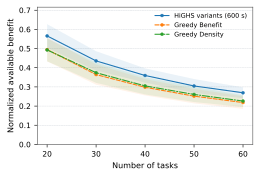

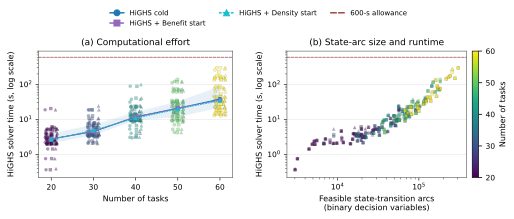

In [4]:
report = export_paper_a(RUN_DIR, png_dpi=PNG_DPI, allow_pilot=(MODE != 'full'))
PAPER_DIR = report['directory']
display(report['quality'][['Tasks', 'Paper method', 'benefit_mean', 'benefit_sd',
                           'tasks_mean', 'certified', 'n', 'shortfall_mean_pct']])
print('Export metadata:', report['metadata'])
print('Output files:', PAPER_DIR)
for name in ['A1_solution_quality_coverage_aware', 'A8_computational_effort']:
    display(SVG(filename=str(PAPER_DIR / (name + '.svg'))))


## Calidad disponible y certificación por presupuesto

A3 y A9-A12 usan el diseño por tamaño de tareas, con los cinco presupuestos.
Los CSV incluyen factibilidad devuelta por HiGHS, media y mediana del incumbent,
su distancia al óptimo conocido y los denominadores de cada media. Un incumbent
ausente sigue ausente; no se presenta como una solución devuelta de valor cero.

La Tabla 1 puntúa por separado el plan idle disponible como cero si cold no
devuelve solución. La certificación y la mejora de inyectar el greedy se calculan
por separado. Las curvas por presupuesto son reinicios independientes, no una
única trayectoria anytime. Los óptimos desconocidos quedan desconocidos.

A10/A11 excluyen incumbents ausentes. Los puntos de muestra parcial indican
sus denominadores; acompañar A11 con A9. A12 expresa la ganancia de
inyección en puntos porcentuales y preserva pérdidas. A13 reúne las
tres métricas de Pedro por límite nominal. A14 usa el reloj observado
dentro de las corridas de 600 s; excluye preparación y no une reinicios.


In [5]:
display(report['budget_quality'])
display(report['attribution'])
SHOW_BUDGET_PLOTS = False
names = ['A3_certification_by_tasks_and_budget', 'A9_budget_feasibility',
         'A10_budget_incumbent_value', 'A11_budget_optimality_shortfall',
         'A12_warm_start_attribution', 'A13_budget_quality_overview', 'A14_observed_anytime_quality']
for name in names:
    print(PAPER_DIR / (name + '.pdf'))
    if SHOW_BUDGET_PLOTS:
        display(SVG(filename=str(PAPER_DIR / (name + '.svg'))))


,Configuration,Tasks,Start Method,Time Limit sec,n,solver_incumbents,available_plans,certified,mean_solver_incumbent,median_solver_incumbent,mean_available_value,n_known_optima,n_known_incumbent_gaps,mean_solver_shortfall_pct,median_solver_shortfall_pct,mean_available_shortfall_pct,mean_measured_seconds,solver_incumbents_pct,available_plans_pct,certified_pct
0,A,20,Cold,1.0,30,2,2,2,0.552915,0.552915,0.036861,30,2,0.000000e+00,0.000000,93.333333,1.766149,6.666667,6.666667,6.666667
1,A,20,Cold,5.0,30,28,28,27,0.562352,0.566946,0.524862,30,28,4.927889e-03,0.000000,6.671266,3.065928,93.333333,93.333333,90.000000
2,A,20,Cold,15.0,30,30,30,29,0.562396,0.566946,0.562396,30,30,4.940610e-01,0.000000,0.494061,3.383268,100.000000,100.000000,96.666667
3,A,20,Cold,60.0,30,30,30,30,0.565866,0.566946,0.565866,30,30,4.373716e-15,0.000000,0.000000,3.506492,100.000000,100.000000,100.000000
4,A,20,Cold,600.0,30,30,30,30,0.565866,0.566946,0.565866,30,30,4.373716e-15,0.000000,0.000000,3.519026,100.000000,100.000000,100.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,A,60,GDStart,1.0,30,30,30,0,0.226171,0.226317,0.226171,30,30,1.613811e+01,15.772877,16.138109,2.402758,100.000000,100.000000,0.000000
71,A,60,GDStart,5.0,30,30,30,0,0.226171,0.226317,0.226171,30,30,1.613811e+01,15.772877,16.138109,7.069398,100.000000,100.000000,0.000000
72,A,60,GDStart,15.0,30,30,30,3,0.232161,0.228271,0.232161,30,30,1.385006e+01,14.659303,13.850059,21.394190,100.000000,100.000000,10.000000
73,A,60,GDStart,60.0,30,30,30,20,0.254338,0.254843,0.254338,30,30,5.336759e+00,0.000000,5.336759,39.920076,100.000000,100.000000,66.666667


,Configuration,Tasks,Start Method,Time Limit sec,n,mean_gain_over_greedy,median_gain_over_greedy,mean_injection_gain,median_injection_gain,improved_greedy,beat_cold_plus_greedy
0,A,20,GBStart,1.0,30,0.006607,0.000000,0.000000e+00,0.0,2,0
1,A,20,GBStart,5.0,30,0.065035,0.062607,-1.187089e-03,0.0,27,1
2,A,20,GBStart,15.0,30,0.068604,0.066078,0.000000e+00,0.0,29,0
3,A,20,GBStart,60.0,30,0.071201,0.068401,0.000000e+00,0.0,30,0
4,A,20,GBStart,600.0,30,0.071201,0.068401,0.000000e+00,0.0,30,0
5,A,20,GDStart,1.0,30,0.007065,0.000000,0.000000e+00,0.0,2,0
6,A,20,GDStart,5.0,30,0.065390,0.060595,-1.895785e-03,0.0,26,1
7,A,20,GDStart,15.0,30,0.069528,0.060595,0.000000e+00,0.0,30,0
8,A,20,GDStart,60.0,30,0.072999,0.063314,0.000000e+00,0.0,30,0
9,A,20,GDStart,600.0,30,0.072999,0.063314,0.000000e+00,0.0,30,0


/Users/educarrascovidal/Documentos/GitHub/Tesis_Doctoral/DISC_TESIS/Resuelto_Paper/ttap_runs_paper_2000dpi/A_paper_full_997dc6f9b016/paper/A3_certification_by_tasks_and_budget.pdf
/Users/educarrascovidal/Documentos/GitHub/Tesis_Doctoral/DISC_TESIS/Resuelto_Paper/ttap_runs_paper_2000dpi/A_paper_full_997dc6f9b016/paper/A9_budget_feasibility.pdf
/Users/educarrascovidal/Documentos/GitHub/Tesis_Doctoral/DISC_TESIS/Resuelto_Paper/ttap_runs_paper_2000dpi/A_paper_full_997dc6f9b016/paper/A10_budget_incumbent_value.pdf
/Users/educarrascovidal/Documentos/GitHub/Tesis_Doctoral/DISC_TESIS/Resuelto_Paper/ttap_runs_paper_2000dpi/A_paper_full_997dc6f9b016/paper/A11_budget_optimality_shortfall.pdf
/Users/educarrascovidal/Documentos/GitHub/Tesis_Doctoral/DISC_TESIS/Resuelto_Paper/ttap_runs_paper_2000dpi/A_paper_full_997dc6f9b016/paper/A12_warm_start_attribution.pdf
/Users/educarrascovidal/Documentos/GitHub/Tesis_Doctoral/DISC_TESIS/Resuelto_Paper/ttap_runs_paper_2000dpi/A_paper_full_997dc6f9b016/paper/A

## Integrar la sección 4.1 en Overleaf

Después de full, subir los dos PDF principales y los .tex de `paper`. Se necesitan
`booktabs`, `makecell` y `graphicx`. `Section_4_1.tex` incluye ambas tablas y figuras
y redacta un texto breve a partir de la corrida, sin asumir mejoras del warm start.
Revisar la interpretación y los nombres de labels antes de sustituir el texto.

Actualizar también el componente de impacto de la sección 3.3 y los numeradores
de ambos greedy, conservando la función temporal. Antes de presentar A, B y
Talcahuano juntos, sus resultados deben usar la misma definición de beneficio.


In [ ]:
for name in ['Table_1_Experiment_A_quality.tex', 'Table_2_Experiment_A_runtime.tex',
             'Section_3_3_impact_update.tex', 'OVERLEAF_README.txt']:
    print(PAPER_DIR / name)
if report['metadata']['full_cohort']:
    print('Section replacement:', PAPER_DIR / 'Section_4_1.tex')
else:
    print('Pilot only: Section_4_1.tex is deliberately not generated.')
